In [2]:
#shooting function
import library
import math
import matplotlib.pyplot as plt

def shooting(f, y0, m, x, n=500):
    if x == 0:
        return [y0, m]
    xs, ys = library.rk4_solve(f, 0.0, [y0, m], x, x / n)
    return ys[-1]

def solve(f, y0, s, x):
    if x == 0:
        return y0, s             
    h = x / 400                        
    xs, ys = library.rk4_solve(f, 0.0, [y0, s], x, h)
    last = ys[-1]                         
    return last[0], last[1]

maximum depression = -0.009999999999999572 m at x = 1.0 m
half maximum = -0.004999999999999786 m at x = 0.3288142681121826 and x = 1.6711857318878174


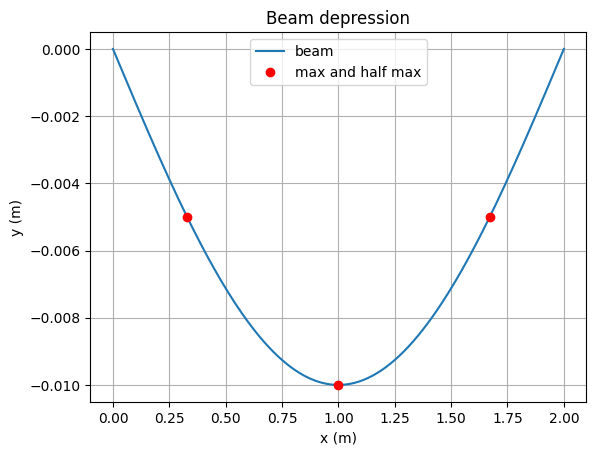

In [ ]:
# determininG the maximum and half-maximum depressions of cantilever beam

import library

a = 0.05
L = 2.0
q = 5000.0
Y = 2.0e11
I = a ** 4 / 12.0            
k = q / (2 * Y * I)

def beam(x, u):
    dy = u[1]
    ddy = -k * x * (x - L)
    return [dy, ddy]

#automatically solves for zeta
def beam_lagrange(zeta):
    y, slope_end = solve(beam, 0.0, zeta, L)
    return y

def beam_slope(x):
    y_x, slope_x = solve(beam, 0.0, s_beam, x)
    return slope_x

reg = library.regfals(beam_lagrange, -1.0, 1.0, 1e-12)
s_beam = reg[0]

result = library.bisection(beam_slope, 0.0, L, 1e-9)
x_max = result[0]
y_max, slope_max = solve(beam, 0.0, s_beam, x_max)
print("maximum depression =", y_max, "m at x =", x_max, "m")

half = y_max / 2

def beam_half(x):
    y_x, slope_x = solve(beam, 0.0, s_beam, x)
    return y_x - half                  

left = library.bisection(beam_half, 0.0, x_max, 1e-9)
right = library.bisection(beam_half, x_max, L, 1e-9)
xh1 = left[0]
xh2 = right[0]
print("half maximum =", half, "m at x =", xh1, "and x =", xh2)

# plot
xs, ys = library.rk4_solve(beam, 0.0, [0.0, s_beam], L, L / 200)
y_values = []
for state in ys:
    y_values.append(state[0])

plt.figure()
plt.plot(xs, y_values, label="beam")
plt.plot([xh1, x_max, xh2], [half, y_max, half], "ro", label="max and half max")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Beam depression")
plt.legend()
plt.grid(True)

starting slope T'(0) = 12.690455737315133
T = 100 C at x = 4.425261910655536 m


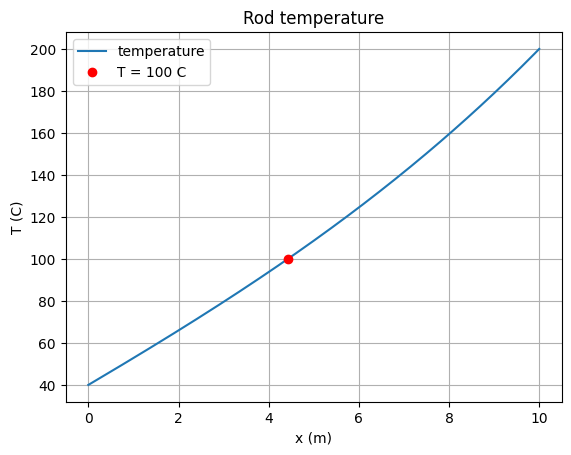

In [ ]:
#heat conduction in a rod
import library

L2 = 10.0
alpha = 0.01
Ta = 20.0
T_start = 40.0
T_end = 200.0

def rod(x, u):
    dT = u[1]
    ddT = alpha * (u[0] - Ta)
    return [dT, ddT]

#automatically solves for zeta
def rod_lagrange(zeta):
    T_at_L, slope_at_L = solve(rod, T_start, zeta, L2)
    return T_at_L - T_end

result = library.regfals(rod_lagrange, -100.0, 100.0, 1e-10)
s_rod = result[0]
print("starting slope T'(0) =", s_rod)

def rod100(x):
    T_x, slope_x = solve(rod, T_start, s_rod, x)
    return T_x - 100.0


result = library.bisection(rod100, 0.0, L2, 1e-9)
x_100 = result[0]
print("T = 100 C at x =", x_100, "m")

# plot
xs, ys = library.rk4_solve(rod, 0.0, [T_start, s_rod], L2, L2 / 200)
T_values = []
for state in ys:
    T_values.append(state[0])

plt.figure()
plt.plot(xs, T_values, label="temperature")
plt.plot([x_100], [100], "ro", label="T = 100 C")
plt.xlabel("x (m)")
plt.ylabel("T (C)")
plt.title("Rod temperature")
plt.legend()
plt.grid(True)

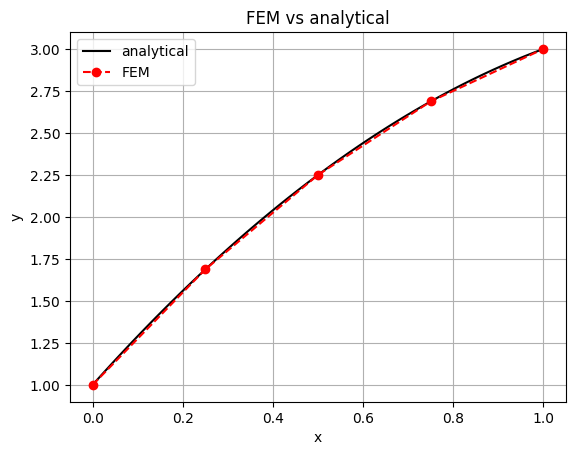

In [10]:
#FEM

n = 4          
h = 1.0 / n
alpha_bc = 1.0       
beta_bc = 3.0            


m = n - 1

K = []
for i in range(m):
    row = []
    for j in range(m):
        if i == j:
            row.append(2.0)
        elif abs(i - j) == 1:
            row.append(-1.0)
        else:
            row.append(0.0)
    K.append(row)

F = []
for i in range(m):
    x = (i + 1) * h                
    F.append(-h * h * (-2.0))

F[0] = F[0] + alpha_bc
F[m - 1] = F[m - 1] + beta_bc

L_matrix = library.cholesky(K)

y_interior = library.forback(L_matrix, F)

x_nodes = []
y_fem = []
for i in range(n + 1):
    x_nodes.append(i * h)

y_fem.append(alpha_bc)
for value in y_interior:
    y_fem.append(value)
y_fem.append(beta_bc)

# plot
x_smooth = []
y_smooth = []
for i in range(101):
    x = i / 100
    x_smooth.append(x)
    y_smooth.append(-x**2 + 3 * x + 1)

plt.figure()
plt.plot(x_smooth, y_smooth, "k-", label="analytical")
plt.plot(x_nodes, y_fem, "ro--", label="FEM")
plt.xlabel("x")
plt.ylabel("y")
plt.title("FEM vs analytical")
plt.legend()
plt.grid(True)

plt.show()